In [5]:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.model_selection import StratifiedGroupKFold
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, f1_score, recall_score, balanced_accuracy_score, precision_score
from sklearn.naive_bayes import MultinomialNB, GaussianNB
from sklearn.preprocessing import StandardScaler, KBinsDiscretizer

In [25]:
nb_labeled = pd.read_csv("../../data/clean/naivebayes/nb_labeled.csv")
nb_labeled.head(8).T.round(2)

,0,1,2,3,4,5,6,7
participant_id,P1,P1,P1,P1,P1,P1,P1,P1
calendarDate,2025-07-13,2025-08-18,2025-08-19,2025-08-20,2025-08-21,2025-08-22,2025-08-23,2025-08-25
cohort,cohort_03,cohort_03,cohort_03,cohort_03,cohort_03,cohort_03,cohort_03,cohort_03
durationInMs,28620000.0,28500000.0,26520000.0,25500000.0,23460000.0,30180000.0,29160000.0,27720000.0
deepSleepDurationInMs,3480000.0,5160000.0,2160000.0,4620000.0,2820000.0,2880000.0,2160000.0,5220000.0
lightSleepDurationInMs,20160000.0,20100000.0,20040000.0,16980000.0,19620000.0,23400000.0,24780000.0,16380000.0
remSleepInMs,4980000.0,3240000.0,4320000.0,3900000.0,1020000.0,3900000.0,2220000.0,6120000.0
awakeDurationInMs,360000.0,780000.0,180000.0,0.0,900000.0,3060000.0,360000.0,0.0
overallSleepScore,79.0,79.0,79.0,80.0,48.0,55.0,47.0,74.0
breathsPerMinute_mean,19.0785,19.163504,18.843708,17.915741,18.371798,18.5172,19.749706,18.339479


In [7]:
y = nb_labeled["low_recovery"]
groups = nb_labeled["participant_id"]

features_to_remove = [
    "participant_id",
    "cohort",
    "calendarDate",
    "low_recovery"
]

X = nb_labeled.drop(columns = features_to_remove)

print(y.shape,X.shape)


(18728,) (18728, 20)


In [8]:
# Train/test split pattern adapted from the scikit-learn StratifiedGroupKFold documentation example
# modified to use a single split and this project's columns.

sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, test_idx = next(sgkf.split(X,y,groups = groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print(f"Train size: {len(train_idx)}")
print(f"Test size: {len(test_idx)}")

Train size: 15003
Test size: 3725


## Correlation Matrix and Cutoffs

In [9]:
from matplotlib.colors import LinearSegmentedColormap

#ai tools used to help verify plotting code was accurate throughout the notebook, not write the code from scratch

print("X_train shape:", X_train.shape)
X_train.head().T

X_train shape: (15003, 20)


,34,35,36,37,38
durationInMs,2.412000e+07,2.262000e+07,2.604000e+07,2.394000e+07,1.794000e+07
deepSleepDurationInMs,7.020000e+06,5.280000e+06,5.700000e+06,5.640000e+06,2.160000e+06
lightSleepDurationInMs,1.170000e+07,9.660000e+06,1.524000e+07,1.314000e+07,1.098000e+07
remSleepInMs,5.400000e+06,7.680000e+06,5.100000e+06,5.160000e+06,4.800000e+06
awakeDurationInMs,6.000000e+04,0.000000e+00,6.000000e+04,1.200000e+05,1.200000e+05
overallSleepScore,7.900000e+01,7.600000e+01,7.300000e+01,8.100000e+01,6.200000e+01
breathsPerMinute_mean,1.603575e+01,1.636830e+01,1.677554e+01,1.697112e+01,1.772412e+01
breathsPerMinute_std,2.567794e+00,2.305960e+00,2.519712e+00,2.117889e+00,2.379074e+00
breathsPerMinute_min,8.000000e+00,7.080000e+00,9.000000e+00,9.250000e+00,8.830000e+00
breathsPerMinute_max,2.258000e+01,2.250000e+01,2.225000e+01,2.175000e+01,2.400000e+01


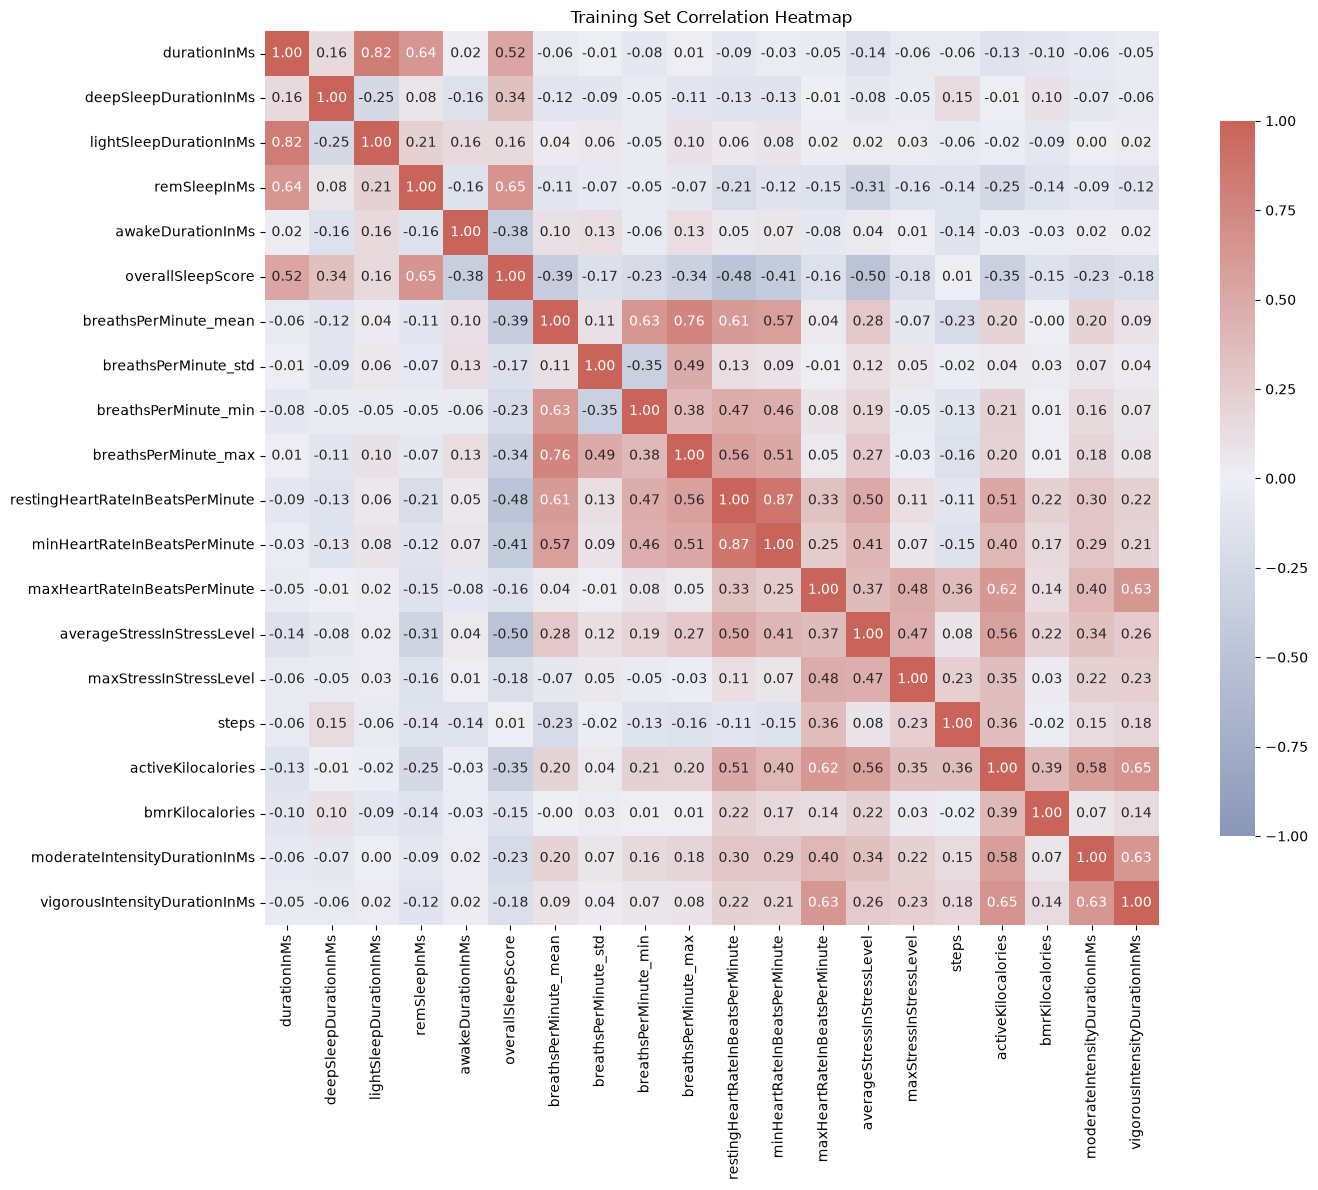

In [10]:
x_train_corr = X_train.corr() #store correlation data
x_train_correlation_data = x_train_corr.copy() 

site_cmap = LinearSegmentedColormap.from_list("site_diverging", ["#8A97B8", "#EDEFF5", "#C9645A"]) #establish suite of theme colors for future correlation heatmap scheme

# Plotting the heatmap
plt.figure(figsize=(15,12))
sns.heatmap(x_train_correlation_data, annot=True, fmt=".2f", cmap=site_cmap, vmin=-1, vmax=1, center=0,
            square=True, cbar_kws={"shrink": .8})
plt.title("Training Set Correlation Heatmap")
plt.tight_layout()
plt.savefig("../../images/naivebayes/nb_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
# code to identify the correlated features above 75%
x_train_corr_columns = list(x_train_correlation_data.columns)

for i in x_train_corr_columns:
    for j in x_train_corr_columns:
        value = x_train_corr.loc[i,j]
        if i < j and abs(value) > 0.75:
            print(i,"|",j,"|", round(value,2))

durationInMs | lightSleepDurationInMs | 0.82
breathsPerMinute_max | breathsPerMinute_mean | 0.76
minHeartRateInBeatsPerMinute | restingHeartRateInBeatsPerMinute | 0.87


In [12]:
#code to reduce features to the below 75% correlation threshold
correlated_features_to_remove = [
    "lightSleepDurationInMs",
    "breathsPerMinute_max",
    "minHeartRateInBeatsPerMinute"
]

X_train = X_train.drop(columns = correlated_features_to_remove)
X_test =  X_test.drop(columns = correlated_features_to_remove)

In [ ]:
pd.concat([X_train,y.iloc[train_idx]], axis = 1).to_csv("../../data/clean/naivebayes/nb_train.csv", index = False)
pd.concat([X_test,y.iloc[test_idx]], axis = 1).to_csv("../../data/clean/naivebayes/nb_test.csv", index = False)

In [32]:
pd.concat([X_train,y.iloc[train_idx]], axis = 1).head(8).round(2).T

,34,35,36,37,38,39,40,41
durationInMs,24120000.0,22620000.0,26040000.0,23940000.0,17940000.0,23880000.0,30600000.0,22260000.0
deepSleepDurationInMs,7020000.0,5280000.0,5700000.0,5640000.0,2160000.0,8820000.0,4260000.0,8460000.0
remSleepInMs,5400000.0,7680000.0,5100000.0,5160000.0,4800000.0,5940000.0,6720000.0,2220000.0
awakeDurationInMs,60000.0,0.0,60000.0,120000.0,120000.0,0.0,60000.0,180000.0
overallSleepScore,79.0,76.0,73.0,81.0,62.0,82.0,84.0,71.0
breathsPerMinute_mean,16.04,16.37,16.78,16.97,17.72,16.27,16.71,16.75
breathsPerMinute_std,2.57,2.31,2.52,2.12,2.38,2.32,2.36,2.55
breathsPerMinute_min,8.0,7.08,9.0,9.25,8.83,8.16,8.75,8.58
restingHeartRateInBeatsPerMinute,57.0,56.0,54.0,55.0,59.0,53.0,54.0,59.0
maxHeartRateInBeatsPerMinute,116.0,109.0,125.0,109.0,119.0,97.0,115.0,115.0


In [33]:
pd.concat([X_test,y.iloc[test_idx]], axis = 1).head(8).round(2).T

,0,1,2,3,4,5,6,7
durationInMs,28620000.0,28500000.0,26520000.0,25500000.0,23460000.0,30180000.0,29160000.0,27720000.0
deepSleepDurationInMs,3480000.0,5160000.0,2160000.0,4620000.0,2820000.0,2880000.0,2160000.0,5220000.0
remSleepInMs,4980000.0,3240000.0,4320000.0,3900000.0,1020000.0,3900000.0,2220000.0,6120000.0
awakeDurationInMs,360000.0,780000.0,180000.0,0.0,900000.0,3060000.0,360000.0,0.0
overallSleepScore,79.0,79.0,79.0,80.0,48.0,55.0,47.0,74.0
breathsPerMinute_mean,19.08,19.16,18.84,17.92,18.37,18.52,19.75,18.34
breathsPerMinute_std,2.25,2.01,2.05,1.81,2.73,2.24,1.74,3.08
breathsPerMinute_min,11.75,13.5,8.75,12.91,7.91,10.83,15.91,7.91
restingHeartRateInBeatsPerMinute,60.0,63.0,62.0,64.0,70.0,65.0,69.0,64.0
maxHeartRateInBeatsPerMinute,133.0,120.0,127.0,112.0,133.0,119.0,136.0,135.0


## Verifying test/train split numbers

In [14]:
print(f"People in both sets: {len(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx]))}")
print(f"People in total: {len(set(groups.iloc[train_idx]) | set(groups.iloc[test_idx]))}")
print(f"{len(groups.iloc[train_idx])} + {len(groups.iloc[test_idx])} = {len(groups.iloc[train_idx]) + len(groups.iloc[test_idx])}")

People in both sets: 0
People in total: 98
15003 + 3725 = 18728


In [15]:
print(f"Training: {groups.iloc[train_idx].nunique()} people, {len(train_idx)} nights, {(y_train.mean()*100).round(2)} low recovery")
print(f"Testing: {groups.iloc[test_idx].nunique()} people, {len(test_idx)} nights, {(y_test.mean()*100).round(2)} low recovery")
print("With training and test split such that there are 79 + 19 = 98 (100%) people and 15003 + 3725 = 18728 (100%) nights, " \
"\n we can conclude that no person appears in both sets")

Training: 79 people, 15003 nights, 10.26 low recovery
Testing: 19 people, 3725 nights, 10.23 low recovery
With training and test split such that there are 79 + 19 = 98 (100%) people and 15003 + 3725 = 18728 (100%) nights, 
 we can conclude that no person appears in both sets


## Multinomial Naive Bayes Testing

In [16]:
kbins = KBinsDiscretizer(n_bins=3, strategy='quantile', encode='onehot')
X_train_binned = kbins.fit_transform(X_train)
X_test_binned = kbins.transform(X_test)

print(f"X_train Shape: {X_train_binned.shape}\n X_test_binned Shape: {X_test_binned.shape}")


X_train Shape: (15003, 49)
 X_test_binned Shape: (3725, 49)


/Users/samuelmeaux/Desktop/Machine Learning/Machine Learning Project - Fall 2026/applied-ml-project/.venv/lib/python3.13/site-packages/sklearn/preprocessing/_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 15 are removed. Consider decreasing the number of bins.
  warnings.warn(
/Users/samuelmeaux/Desktop/Machine Learning/Machine Learning Project - Fall 2026/applied-ml-project/.venv/lib/python3.13/site-packages/sklearn/preprocessing/_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 16 are removed. Consider decreasing the number of bins.
  warnings.warn(


In [17]:
multiNB = MultinomialNB()
multiNB.fit(X = X_train_binned, y = y_train) # X_train here is our feature matrix , y_train is the binary aka low recovery/not low recovery
predictions = multiNB.predict(X_test_binned)
print(sum(predictions))

432


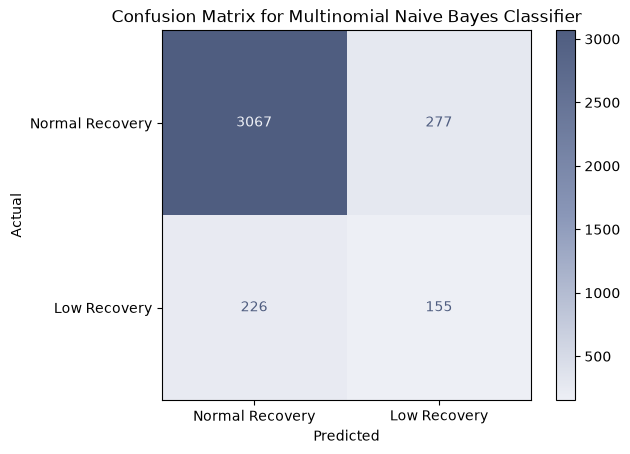

In [18]:
# code adapted from inclass notebook
# Generating the confusion matrix


nb_cmap = LinearSegmentedColormap.from_list("site_diverging", ["#EDEFF5", "#8A97B8", "#4F5D80"]) #establish suite of theme colors
cm = confusion_matrix(y_test, predictions)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Normal Recovery","Low Recovery"])
disp.plot(cmap = nb_cmap)
disp.ax_.set_xlabel("Predicted")
disp.ax_.set_ylabel("Actual")
disp.ax_.set_title('Confusion Matrix for Multinomial Naive Bayes Classifier');
plt.savefig("../../images/naivebayes/multinomial_confusion_matrix.png", dpi=150, bbox_inches="tight")

In [19]:
# Accuracy, F1 Score and Recall Score

accuracy = np.round(accuracy_score(y_test, predictions),3)

# accuracy = (TP + TN)/ total  -- measures the overall correctness aka how many predictions 
# were correct 


f1 = np.round(f1_score(y_test, predictions),3)

# 2 x (Precision x Recall) / (Precision + Recall) -- balances precision and recall and is useful when you care about both false positive and false negatives and also when your data is imbalanced 

recall = np.round(recall_score(y_test, predictions),3)
bas = np.round(balanced_accuracy_score(y_test, predictions),3)
ps = np.round(precision_score(y_test, predictions),3)
baseline = np.round(1 - y_test.mean(),3)

# TP/ (TP + FN ) -- Also called sensitivity or TPR (true positive rate) and this measures how well the model catches the positive class and this is important in cases like disease detection, fraud etc where missing positive is COSTLY!!!

print(f'Accuracy: {accuracy}')
print(f'F1 Score: {f1}')
print(f'Recall Score: {recall}')
print(f'Balanced Accuracy Score: {bas}')
print(f'Precision Score: {ps}')
print(f'Baseline Accuracy if model predicts "no" for every observation: {baseline}')

Accuracy: 0.865
F1 Score: 0.381
Recall Score: 0.407
Balanced Accuracy Score: 0.662
Precision Score: 0.359
Baseline Accuracy if model predicts "no" for every observation: 0.898


### Interpretations:

* Accuracy (86.5%) is below the baseline of 89.8% since the data is lopsided
* The balanced accuracy is 66% vs a 50% do-nothing model - the model is picking up a signal
* Recall is 41% is about 4 in 10 low-recovery nights are being caught
* Precision is 36% so about 1 in 3 of its flags are a true positive.

## Gaussian Naive Bayes Testing

In [20]:
# code adapted from in class notebook
# implementing the NAIVE BAYES Classifier 


sc = StandardScaler()
sc_X_train  = sc.fit_transform(X_train)
classifier = GaussianNB()  #used to fit the model and later make predictions 
classifier.fit(sc_X_train, y_train) # X_train here is our feature matrix , y_train is the binary aka low recovery/not low recovery


# under the hood it estimates the mean and variance of each feature per class (for Gaussian Probability) and it also calculates prior probabilities of each class (how often each class occurs)

preds = classifier.predict(sc.transform(X_test)) # Predicting the Test set

# using the trained classifer to predict the class labels ( 0 or 1) for test data thus returning an array of predicted labels for the test set. 

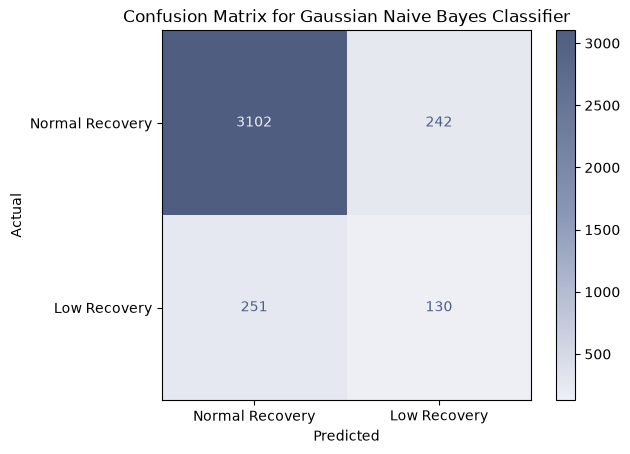

In [23]:
gcm = confusion_matrix(y_test, preds)

disp = ConfusionMatrixDisplay(confusion_matrix=gcm, display_labels=["Normal Recovery","Low Recovery"])
disp.plot(cmap = nb_cmap)
disp.ax_.set_xlabel("Predicted")
disp.ax_.set_ylabel("Actual")
disp.ax_.set_title('Confusion Matrix for Gaussian Naive Bayes Classifier');
plt.savefig("../../images/naivebayes/gaussian_confusion_matrix.png", dpi=150, bbox_inches="tight")

In [22]:
# Accuracy, F1 Score and Recall Score

g_accuracy = np.round(accuracy_score(y_test, preds),3)

# accuracy = (TP + TN)/ total  -- measures the overall correctness aka how many predictions 
# were correct 


g_f1 = np.round(f1_score(y_test, preds),3)

# 2 x (Precision x Recall) / (Precision + Recall) -- balances precision and recall and is useful when you care about both false positive and false negatives and also when your data is imbalanced 

g_recall = np.round(recall_score(y_test, preds),3)
g_bas = np.round(balanced_accuracy_score(y_test, preds),3)
g_ps = np.round(precision_score(y_test, preds),3)
g_baseline = np.round(1 - y_test.mean(),3)

# TP/ (TP + FN ) -- Also called sensitivity or TPR (true positive rate) and this measures how well the model catches the positive class and this is important in cases like disease detection, fraud etc where missing positive is COSTLY!!!

print(f'Accuracy: {g_accuracy}')
print(f'F1 Score: {g_f1}')
print(f'Recall Score: {g_recall}')
print(f'Balanced Accuracy Score: {g_bas}')
print(f'Precision Score: {g_ps}')
print(f'Baseline Accuracy if model predicts "no" for every observation: {g_baseline}')

Accuracy: 0.868
F1 Score: 0.345
Recall Score: 0.341
Balanced Accuracy Score: 0.634
Precision Score: 0.349
Baseline Accuracy if model predicts "no" for every observation: 0.898


### Interpretations:

* Accuracy (86.8%) is still below the baseline of 89.8% and barely better than the Multinomial Model
* The balanced accuracy is 63.4% vs a 50% do-nothing model - the model is still picking up a signal
* Recall is 34.1% is about 3 in 10 low-recovery nights are being caught, worse than Multinomial
* Precision is 34.9% so about 1 in 3 of its flags are still true positive.